# Практическая работа 3. Предобработка данных.

Выполнил: Мешков Егор Константинович, группа Д-Э 18-24

Цель работы: научиться выполнять предобработку и разведочный анализ данных на примере датасета Iris.

Ссылка для скачивания датасета:
https://raw.githubusercontent.com/kalitvin/kalitvin.github.io/refs/heads/main/notebooks/iris/iris_teach.csv

## Iris Dataset

Набор данных Iris был представлен миру британским статистиком и генетиком Рональдом Фишером в 1936 году в его революционной статье "The use of multiple measurements in taxonomic problems". Фишер использовал этот набор для демонстрации линейного дискриминантного анализа - методики, которая спустя почти столетие продолжает оставаться актуальной и эффективной.

Данные были собраны биологом Эдгаром Андерсоном на полуострове Гаспе в Канаде. Он измерил четыре характеристики у 150 экземпляров ирисов трёх видов: Iris setosa, Iris versicolor и Iris virginica. Этот простой и изящный набор данных заложил основы для множества алгоритмов машинного обучения, которые мы используем сегодня.

Ключевые причины, по которым Iris dataset стал эталоном в машинном обучении:

Идеальный размер: 150 образцов - достаточно для анализа, но не настолько много, чтобы вызвать проблемы производительности

Сбалансированные классы: по 50 образцов каждого вида, что создаёт идеальные условия для обучения

Многомерность: четыре признака позволяют исследовать многомерные отношения

Различимость классов: один класс (Setosa) линейно отделим, а два других (Versicolor и Virginica) частично перекрываются, создавая интересную задачу для алгоритмов

В настоящее время исследователи и аналитики данных продолжают использовать Iris dataset как отправную точку для обучения и тестирования новых алгоритмов.

Набор данных Iris состоит из 150 образцов ирисов, разделенных на три вида. Каждый образец характеризуется четырьмя признаками: длиной и шириной чашелистика (sepal length and width), а также длиной и шириной лепестка (petal length and width). Все измерения представлены в сантиметрах.

## Изучение данных из файла

Загрузка данных и проверка структуры (типы признаков, размерность, форматы).

Импортируем библиотеку pandas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Считываем данные из файла .csv и сохраняем в переменной df

In [2]:
# df = pd.read_csv("iris_teach.csv")
df = pd.read_csv("https://kalitvin.github.io/notebooks/iris/iris_teach.csv")

Получим первые 10 строк таблицы с данными

In [3]:
df.head(10)

,Id,Sepal Length Cm,Sepal Width (Cm),Petal-Length-Cm,Petal-WIDTH(Cm),SPECIES,unit
0,1,??,3.5,1.4,0.2,Iris-setosa,cm
1,2,very_long,3.0,1.4,0.2,Iris-setosa,cm
2,3,NaN,3.2,1.3,0.2,Iris-setosa,cm
3,4,4.6,3.1,1.5,0.2,Iris-setosa,cm
4,5,5.0,3.6,1.4,0.2,Iris-setosa,cm
5,6,5.4,3.9,1.7,0.4,setsoa,cm
6,7,4.6,3.4,1.4,0.3,Iris-setosa,cm
7,8,5.0,3.4,1.5,0.2,Iris-setosa,cm
8,9,4.4,2.9,NaN,0.2,Iris-setosa,cm
9,10,4.9,3.1,1.5,0.1,Iris-setosa,cm


Получим информацию о таблице с данными

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Id                185 non-null    int64  
 1   Sepal Length Cm   170 non-null    str    
 2   Sepal Width (Cm)  185 non-null    float64
 3   Petal-Length-Cm   171 non-null    float64
 4   Petal-WIDTH(Cm)   185 non-null    float64
 5   SPECIES           185 non-null    str    
 6   unit              185 non-null    str    
dtypes: float64(3), int64(1), str(3)
memory usage: 10.2 KB


В таблице 6 колонок (и еще служебная колонка unit с единицами измерения):

* 0 Id - Порядковый номер. (тип данных int64 - целое число).
* 1 SepalLengthCm - Длина чашелистика (наружный лепесток цветка) в сантиметрах. Это числовой признак, отражающий общий размер цветка по одной из осей. (тип данных float64 - вещественное число).
* 2 SepalWidthCm - Ширина чашелистика в сантиметрах. Ещё один линейный размер цветка; вместе с длиной образует грубую характеристику «размера и формы» цветка. (тип данных float64 - вещественное число)
* 3 PetalLengthCm - Длина лепестка в сантиметрах. Очень информативный признак для разделения видов: у Iris setosa лепестки существенно короче, чем у двух других видов. (тип данных float64 - вещественное число)
* 4 PetalWidthCm - Ширина лепестка в сантиметрах. В связке с длиной лепестка позволяет почти идеально разделить три вида (особенно отделить setosa). (тип данных float64 - вещественное число)
* 5 Species - Вид ириса (целевая переменная для классификации): setosa; versicolor; virginica. (тип данных object - строка)

В sklearn по умолчанию data содержит только 4 числовых признака, а target - это массив из 0, 1, 2, соответствующих этим трём видам; имена видов лежат в target_names. Если загружать с as_frame=True, в frame появится сразу и признаки, и столбец вида.

In [5]:
df.columns

Index(['Id', 'Sepal Length Cm', 'Sepal Width (Cm)', 'Petal-Length-Cm',
       'Petal-WIDTH(Cm)', 'SPECIES', 'unit'],
      dtype='str')

## Название колонок

**Базовые принципы**

Осмысленные имена. Название должно описывать, что в колонке лежит: sepal_length, body_mass_g, crop_yield_t_ha, а не x1, col3.

Единый стиль по всему проекту. Не мешать sepalLength, Sepal_length и sepal_length в одном датасете.

Без пробелов и спецсимволов. Лучше sepal_length вместо Sepal length (cm) - проще писать код и меньше сюрпризов при merge/SQL.

Рекомендуемый стиль В Python-экосистеме обычно берут:

snake_case:

всё в нижнем регистре;

слова разделены подчёркиваниями: sepal_length, petal_width, student_age.

Дополнительно (по желанию команды/курса):

Префиксы по типу данных: n_ для чисел, c_ для категорий и т.п. (n_area, c_species) - удобно в больших ML-таблицах.

Единицы измерения в имени: sepal_length_cm, yield_t_ha, body_mass_g.

Чего лучше избегать Пробелы, дефисы, скобки: Sepal length (cm), petal-length. Лучше sepal_length_cm.

Очень короткие аббревиатуры, понятные только автору (sl, pl без контекста).

**Корректировка названий колонок**

Сейчас названия написаны в разном стиле: где-то пробелы, где-то дефисы, скобки и заглавные буквы. Переименуем все колонки в snake_case и оставим единицы измерения в названии.

In [6]:
df = df.rename(columns={
    "Id": "id",
    "Sepal Length Cm": "sepal_length_cm",
    "Sepal Width (Cm)": "sepal_width_cm",
    "Petal-Length-Cm": "petal_length_cm",
    "Petal-WIDTH(Cm)": "petal_width_cm",
    "SPECIES": "species",
    "unit": "unit",
})
df.columns

Index(['id', 'sepal_length_cm', 'sepal_width_cm', 'petal_length_cm',
       'petal_width_cm', 'species', 'unit'],
      dtype='str')

**Выявление проблем: пропуски, дубликаты, выбросы, противоречивые и «странные» значения.**

Сначала посчитаем пропуски в каждой колонке.

In [7]:
df.isna().sum()

id                  0
sepal_length_cm    15
sepal_width_cm      0
petal_length_cm    14
petal_width_cm      0
species             0
unit                0
dtype: int64

Колонка sepal_length_cm должна быть числовой, но pandas прочитал ее как строку. Значит, в ней есть значения, которые не являются числами. Найдем их.

In [8]:
# to_numeric с errors="coerce" превращает все, что не число, в NaN
not_number = pd.to_numeric(df["sepal_length_cm"], errors="coerce").isna() & df["sepal_length_cm"].notna()
df.loc[not_number, ["id", "sepal_length_cm"]]

,id,sepal_length_cm
0,1,??
1,2,very_long


Посмотрим, какие значения есть в колонках species и unit.

In [9]:
print(df["species"].value_counts())
print()
print(df["unit"].value_counts())

species
Iris-setosa        58
Iris-virginica     57
Iris-versicolor    56
virginica           7
versi color         5
setsoa              1
unknown             1
Name: count, dtype: int64

unit
cm    175
mm     10
Name: count, dtype: int64


Проверим дубликаты: полностью одинаковые строки и повторяющиеся id.

In [10]:
print("Полных дубликатов строк:", df.duplicated().sum())
print("Повторяющихся id:", df["id"].duplicated().sum())
print("Всего строк:", len(df), ", уникальных id:", df["id"].nunique())

Полных дубликатов строк: 14
Повторяющихся id: 35
Всего строк: 185 , уникальных id: 150


Посмотрим на статистику по числовым колонкам, чтобы увидеть выбросы.

In [11]:
df["sepal_length_cm"] = pd.to_numeric(df["sepal_length_cm"], errors="coerce")
df.describe()

,id,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,185.000000,168.000000,185.000000,171.000000,185.000000
mean,75.805405,9.229167,4.647027,6.181871,2.347027
std,43.294680,13.595219,6.695481,10.510044,4.443988
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.000000,5.200000,2.800000,1.600000,0.400000
50%,76.000000,5.800000,3.000000,4.500000,1.400000
75%,112.000000,6.525000,3.400000,5.400000,2.000000
max,150.000000,73.000000,44.000000,63.000000,25.000000


Строки с единицей измерения mm:

In [12]:
df[df["unit"] == "mm"]

,id,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,unit
175,149,62.0,34.0,54.0,23.0,Iris-virginica,mm
176,109,67.0,25.0,58.0,18.0,virginica,mm
177,57,63.0,33.0,47.0,16.0,Iris-versicolor,mm
178,108,73.0,29.0,63.0,18.0,Iris-virginica,mm
179,113,68.0,30.0,55.0,21.0,Iris-virginica,mm
180,72,61.0,28.0,40.0,13.0,Iris-versicolor,mm
181,16,57.0,44.0,15.0,4.0,Iris-setosa,mm
182,23,46.0,36.0,10.0,2.0,Iris-setosa,mm
183,117,65.0,30.0,55.0,18.0,Iris-virginica,mm
184,52,64.0,32.0,45.0,15.0,Iris-versicolor,mm


**Найденные проблемы:**

1. Названия колонок в разном стиле (уже исправлено).
2. В sepal_length_cm есть текстовые значения `??` и `very_long`, из-за них колонка была строковой. Их превращаем в пропуски.
3. Пропуски: 17 в sepal_length_cm (15 исходных и 2 из текстовых значений) и 14 в petal_length_cm.
4. Названия видов записаны по-разному: `virginica`, `versi color`, опечатка `setsoa`, лишние пробелы, а у одной строки вид `unknown`.
5. 10 строк записаны в миллиметрах (unit = mm), поэтому у них значения в 10 раз больше, например длина чашелистика 73 вместо 7.3.
6. В таблице 185 строк, а уникальных id только 150, то есть есть повторы. Часть повторов станет полными дубликатами только после исправления видов и единиц измерения.
7. В petal_width_cm есть значения 13, 18, 24, 25 у строк с unit = cm. Ширина лепестка ириса не больше 2.5 см, так что это ошибки ввода. Еще одну такую ошибку (2.0 у setosa) видно только при проверке по видам, она разобрана ниже.

## Очистка данных

Удаление или объединение дубликатов.

Перед поиском дубликатов приведем к одному виду названия видов и единицы измерения, иначе одинаковые цветки не будут считаться дубликатами.

In [13]:
# убираем пробелы по краям и исправляем разные написания
df["species"] = df["species"].str.strip()
df["species"] = df["species"].replace({
    "setsoa": "Iris-setosa",
    "versi color": "Iris-versicolor",
    "virginica": "Iris-virginica",
})
df["species"].value_counts()

species
Iris-virginica     64
Iris-versicolor    61
Iris-setosa        59
unknown             1
Name: count, dtype: int64

In [14]:
num_cols = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]

# переводим миллиметры в сантиметры
mm = df["unit"] == "mm"
df.loc[mm, num_cols] = df.loc[mm, num_cols] / 10
df.loc[mm, "unit"] = "cm"

df["unit"].value_counts()

unit
cm    185
Name: count, dtype: int64

Строку с видом unknown удаляем: вид это целевая переменная, без нее строка для обучения бесполезна.

In [15]:
df = df[df["species"] != "unknown"]
len(df)

184

Теперь удаляем дубликаты.

In [16]:
print("Строк до удаления дубликатов:", len(df))
df = df.drop_duplicates()
print("Строк после:", len(df))
print("Повторяющихся id:", df["id"].duplicated().sum())

Строк до удаления дубликатов: 184
Строк после: 149
Повторяющихся id: 0


Осталось 149 строк, все id уникальные: исходные 150 цветков минус строка с unknown.

Обработка пропущенных значений: удаление строк/столбцов или заполнение статистическими и/или модельными методами.

In [17]:
df.isna().sum()

id                  0
sepal_length_cm    17
sepal_width_cm      0
petal_length_cm    14
petal_width_cm      0
species             0
unit                0
dtype: int64

Удалять строки не будем, иначе потеряем около 20% данных. Заполним пропуски медианой, причем отдельно для каждого вида: размеры у видов сильно отличаются, и общая медиана была бы неточной. Медиана меньше зависит от выбросов, чем среднее.

In [18]:
for col in ["sepal_length_cm", "petal_length_cm"]:
    df[col] = df[col].fillna(df.groupby("species")[col].transform("median"))

df.isna().sum()

id                 0
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
unit               0
dtype: int64

Обработка выбросов и шума: фильтрация, обрезка, замена, устойчивые оценки.

Найдем выбросы по правилу межквартильного размаха (IQR): выбросом считается значение, которое дальше чем на 1.5 * IQR от первого или третьего квартиля.

In [19]:
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    out = df[(df[col] < low) | (df[col] > high)]
    print(col, ": границы", round(low, 2), "-", round(high, 2), ", выбросов:", len(out))
    if len(out) > 0:
        print(out[["id", col, "species"]])

sepal_length_cm : границы 3.15 - 8.35 , выбросов: 0
sepal_width_cm : границы 2.05 - 4.05 , выбросов: 4
    id  sepal_width_cm          species
15  16             4.4      Iris-setosa
32  33             4.1      Iris-setosa
33  34             4.2      Iris-setosa
60  61             2.0  Iris-versicolor
petal_length_cm : границы -3.65 - 10.35 , выбросов: 0
petal_width_cm : границы -1.95 - 4.05 , выбросов: 4
      id  petal_width_cm          species
89    90            13.0  Iris-versicolor
109  110            25.0   Iris-virginica
114  115            24.0   Iris-virginica
123  124            18.0   Iris-virginica


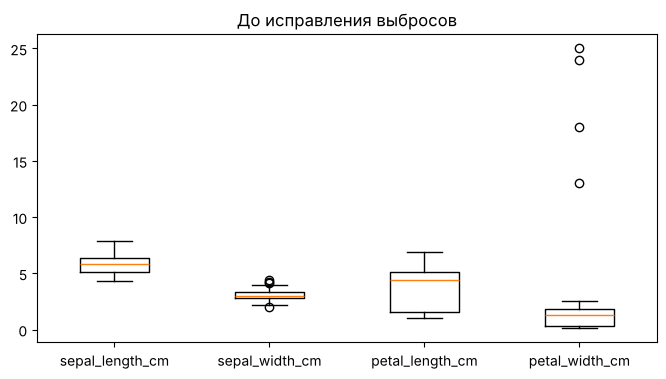

In [20]:
plt.figure(figsize=(8, 4))
plt.boxplot([df[c] for c in num_cols])
plt.xticks([1, 2, 3, 4], num_cols)
plt.title("До исправления выбросов")
plt.show()

Выбросы в petal_width_cm (13, 18, 24, 25) это явно пропущенная запятая: у тех же цветков в остальном нормальные размеры, а 1.3, 1.8, 2.4, 2.5 как раз типичные значения для их видов. Поэтому такие значения не удаляем, а делим на 10.

Значения sepal_width_cm 2.0, 4.1, 4.2, 4.4 формально выходят за границы, но это реальные размеры цветков из исходного датасета, их оставляем.

In [21]:
wrong = df["petal_width_cm"] > 3
print(df.loc[wrong, ["id", "petal_width_cm", "species"]])
df.loc[wrong, "petal_width_cm"] = df.loc[wrong, "petal_width_cm"] / 10
print()
print(df.loc[wrong, ["id", "petal_width_cm", "species"]])

      id  petal_width_cm          species
89    90            13.0  Iris-versicolor
109  110            25.0   Iris-virginica
114  115            24.0   Iris-virginica
123  124            18.0   Iris-virginica

      id  petal_width_cm          species
89    90             1.3  Iris-versicolor
109  110             2.5   Iris-virginica
114  115             2.4   Iris-virginica
123  124             1.8   Iris-virginica


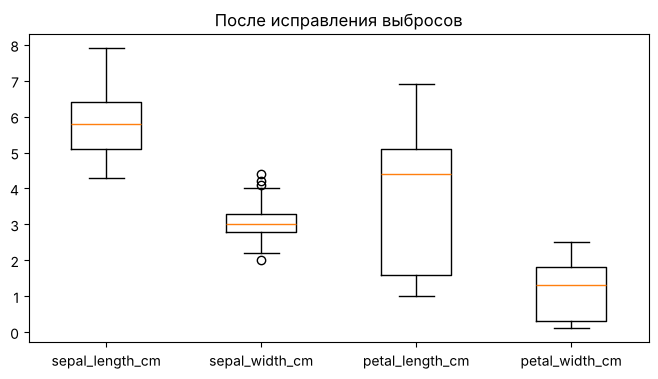

In [22]:
plt.figure(figsize=(8, 4))
plt.boxplot([df[c] for c in num_cols])
plt.xticks([1, 2, 3, 4], num_cols)
plt.title("После исправления выбросов")
plt.show()

Общая проверка не учитывает, что у разных видов разные размеры. Значение, нормальное для virginica, может быть ошибкой для setosa. Поэтому посмотрим ширину лепестка отдельно по видам.

In [23]:
for s in ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]:
    part = df[df["species"] == s]["petal_width_cm"]
    print(s, ": min", part.min(), ", median", part.median(), ", max", part.max())

print()
print(df[(df["species"] == "Iris-setosa") & (df["petal_width_cm"] > 1)][["id", "petal_width_cm", "species"]])

Iris-setosa : min 0.1 , median 0.2 , max 2.0
Iris-versicolor : min 1.0 , median 1.3 , max 1.8
Iris-virginica : min 1.4 , median 2.0 , max 2.5

    id  petal_width_cm      species
20  21             2.0  Iris-setosa


У setosa ширина лепестка от 0.1 до 0.6 см, а у цветка с id 21 она 2.0 см, в 10 раз больше медианы вида. Остальные размеры этого цветка обычные для setosa, значит это та же ошибка с запятой: исправляем на 0.2.

In [24]:
wrong_setosa = (df["species"] == "Iris-setosa") & (df["petal_width_cm"] > 1)
df.loc[wrong_setosa, "petal_width_cm"] = df.loc[wrong_setosa, "petal_width_cm"] / 10
df[df["id"] == 21]

,id,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,unit
20,21,5.4,3.4,1.7,0.2,Iris-setosa,cm


## Преобразование и нормализация признаков

Приведение типов

In [25]:
# колонка unit теперь везде cm, информации не несет, удаляем
df = df.drop(columns="unit")
# вид это категория, а не произвольный текст
df["species"] = df["species"].astype("category")
df = df.reset_index(drop=True)
df.dtypes

id                    int64
sepal_length_cm     float64
sepal_width_cm      float64
petal_length_cm     float64
petal_width_cm      float64
species            category
dtype: object

Масштабирование числовых признаков

Признаки имеют разный масштаб (длина чашелистика 4-8 см, ширина лепестка 0.1-2.5 см). Многие модели чувствительны к масштабу, поэтому приведем признаки к среднему 0 и стандартному отклонению 1 с помощью StandardScaler.

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df_scaled = df.copy()
df_scaled[num_cols] = scaler.fit_transform(df[num_cols])

df_scaled[num_cols].describe().round(2)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,149.00,149.00,149.00,149.00
mean,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-1.94,-2.44,-1.59,-1.46
25%,-0.93,-0.58,-1.25,-1.19
50%,-0.04,-0.12,0.34,0.12
75%,0.71,0.58,0.74,0.78
max,2.61,3.14,1.76,1.71


Кодирование категориальных признаков

Вид ириса переведем в число 0, 1, 2, как в sklearn. Так как это целевая переменная, а не признак, порядок чисел ни на что не влияет.

In [27]:
species_codes = {"Iris-setosa": 0, "Iris-versicolor": 1, "Iris-virginica": 2}
df["species_code"] = df["species"].map(species_codes).astype(int)
df[["species", "species_code"]].drop_duplicates()

,species,species_code
0,Iris-setosa,0
49,Iris-versicolor,1
99,Iris-virginica,2


## Сокращение и отбор признаков

Колонка id это просто номер строки, на вид цветка она не влияет. Посмотрим, как связаны признаки между собой и с видом.

In [28]:
corr = df[num_cols + ["species_code"]].corr().round(2)
corr

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species_code
sepal_length_cm,1.00,-0.11,0.86,0.82,0.79
sepal_width_cm,-0.11,1.00,-0.43,-0.35,-0.41
petal_length_cm,0.86,-0.43,1.00,0.96,0.95
petal_width_cm,0.82,-0.35,0.96,1.00,0.96
species_code,0.79,-0.41,0.95,0.96,1.00


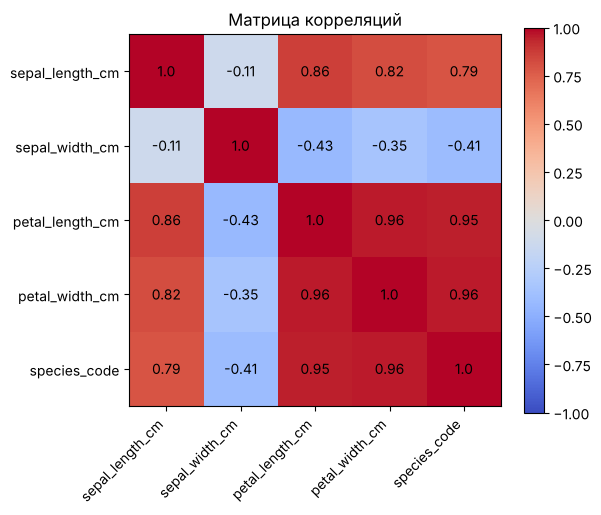

In [29]:
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, corr.iloc[i, j], ha="center", va="center")
plt.title("Матрица корреляций")
plt.show()

In [30]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(f_classif, k=2)
selector.fit(df[num_cols], df["species_code"])
print(pd.Series(selector.scores_, index=num_cols).sort_values(ascending=False).round(1))
best = [c for c, keep in zip(num_cols, selector.get_support()) if keep]
print("Лучшие 2 признака:", best)

petal_length_cm    1262.4
petal_width_cm      941.3
sepal_length_cm     122.1
sepal_width_cm       45.8
dtype: float64
Лучшие 2 признака: ['petal_length_cm', 'petal_width_cm']


Вывод: сильнее всего с видом связаны размеры лепестка (petal_length_cm и petal_width_cm), причем они сильно связаны и между собой. Ширина чашелистика связана с видом слабее всех. Признаков всего 4, поэтому для модели оставляем все четыре, а id удаляем. Если нужно сократить число признаков, достаточно двух признаков лепестка.

In [31]:
df = df.drop(columns="id")
df.head()

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species,species_code
0,5.0,3.5,1.4,0.2,Iris-setosa,0
1,5.0,3.0,1.4,0.2,Iris-setosa,0
2,5.0,3.2,1.3,0.2,Iris-setosa,0
3,4.6,3.1,1.5,0.2,Iris-setosa,0
4,5.0,3.6,1.4,0.2,Iris-setosa,0


## EDA (Разведочный анализ данных)

In [32]:
df.describe().round(2)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species_code
count,149.00,149.00,149.00,149.00,149.00
mean,5.83,3.05,3.80,1.21,1.01
std,0.79,0.43,1.76,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.40,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


Количество цветков каждого вида: классы почти сбалансированы.

In [33]:
df["species"].value_counts()

species
Iris-versicolor    50
Iris-virginica     50
Iris-setosa        49
Name: count, dtype: int64

Средние размеры по видам:

In [34]:
df.groupby("species", observed=True)[num_cols].mean().round(2)

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
species,,,,
Iris-setosa,5.02,3.41,1.48,0.24
Iris-versicolor,5.92,2.77,4.31,1.33
Iris-virginica,6.55,2.97,5.57,2.03


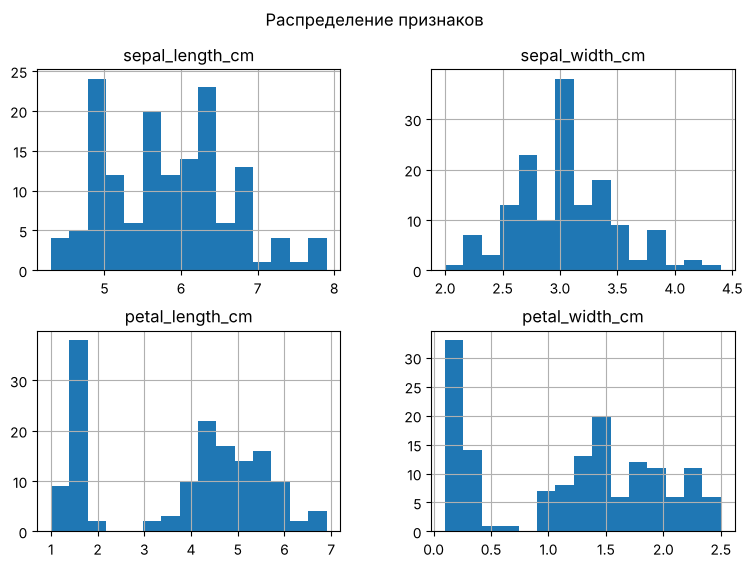

In [35]:
df[num_cols].hist(bins=15, figsize=(9, 6))
plt.suptitle("Распределение признаков")
plt.show()

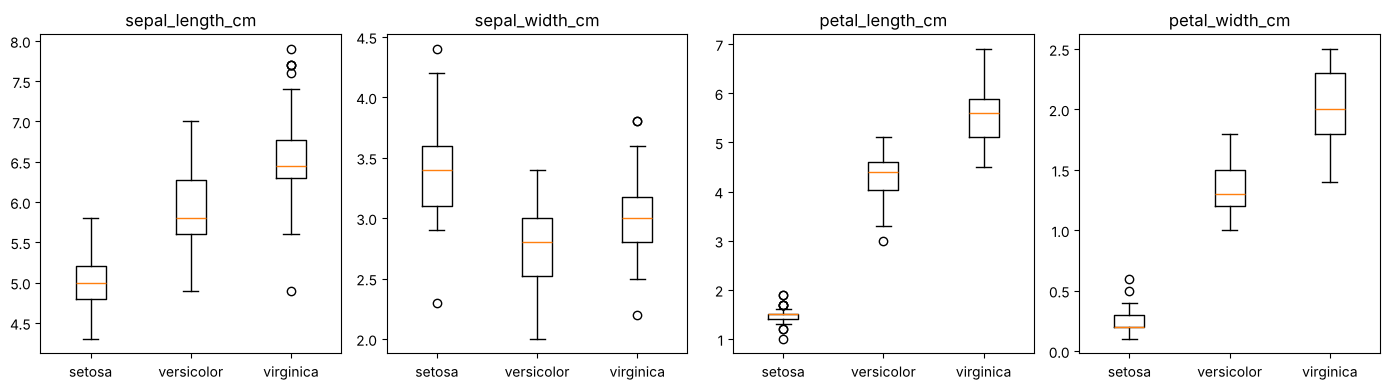

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for i, col in enumerate(num_cols):
    data = [df[df["species"] == s][col] for s in species_codes]
    axes[i].boxplot(data)
    axes[i].set_xticks([1, 2, 3], ["setosa", "versicolor", "virginica"])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

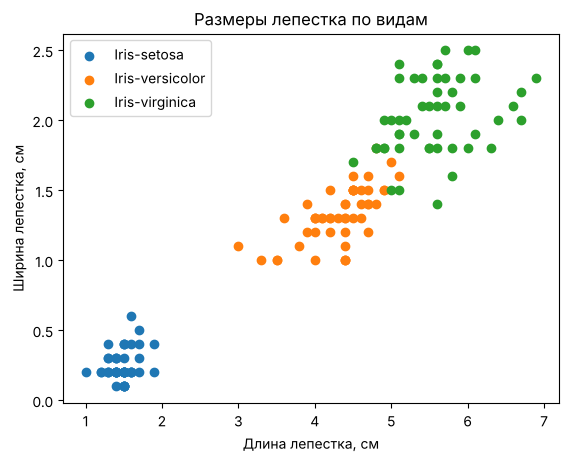

In [37]:
for s in species_codes:
    part = df[df["species"] == s]
    plt.scatter(part["petal_length_cm"], part["petal_width_cm"], label=s)
plt.xlabel("Длина лепестка, см")
plt.ylabel("Ширина лепестка, см")
plt.legend()
plt.title("Размеры лепестка по видам")
plt.show()

Выводы по EDA:

* у признаков лепестка распределение с двумя «горбами»: отдельная группа маленьких значений это setosa;
* setosa полностью отделяется от остальных по длине и ширине лепестка;
* versicolor и virginica немного пересекаются, virginica в среднем крупнее;
* по ширине чашелистика виды различаются слабо, setosa в среднем даже шире остальных.

## Финальная подготовка к обучению

Разделение на train/validation/test.

Делим данные на обучающую (70%), валидационную (15%) и тестовую (15%) выборки. stratify сохраняет одинаковую долю видов во всех частях, random_state делает разбиение повторяемым.

In [38]:
from sklearn.model_selection import train_test_split

X = df[num_cols]
y = df["species_code"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print("train:", X_train.shape, " validation:", X_val.shape, " test:", X_test.shape)
print(y_train.value_counts().sort_index().tolist(), y_val.value_counts().sort_index().tolist(), y_test.value_counts().sort_index().tolist())

train: (104, 4)  validation: (22, 4)  test: (23, 4)
[34, 35, 35] [8, 7, 7] [7, 8, 8]


Автоматизация всех шагов предобработки (создания конвейера - pipeline).

Соберем все шаги очистки в одну функцию, чтобы такой же сырой файл можно было обработать одной строкой. Затем сделаем конвейер sklearn: заполнение пропусков, масштабирование и модель. В конвейере масштаб считается только по обучающей выборке, поэтому данные из validation и test не «подсматриваются».

In [39]:
def clean_iris(raw):
    data = raw.copy()
    data.columns = ["id", "sepal_length_cm", "sepal_width_cm", "petal_length_cm",
                    "petal_width_cm", "species", "unit"]
    cols = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
    data["sepal_length_cm"] = pd.to_numeric(data["sepal_length_cm"], errors="coerce")
    data["species"] = data["species"].str.strip().replace({
        "setsoa": "Iris-setosa",
        "versi color": "Iris-versicolor",
        "virginica": "Iris-virginica",
    })
    mm = data["unit"] == "mm"
    data.loc[mm, cols] = data.loc[mm, cols] / 10
    data = data[data["species"] != "unknown"].drop(columns="unit")
    data = data.drop_duplicates()
    wrong = (data["petal_width_cm"] > 3) | ((data["species"] == "Iris-setosa") & (data["petal_width_cm"] > 1))
    data.loc[wrong, "petal_width_cm"] = data.loc[wrong, "petal_width_cm"] / 10
    for col in ["sepal_length_cm", "petal_length_cm"]:
        data[col] = data[col].fillna(data.groupby("species")[col].transform("median"))
    return data.drop(columns="id").reset_index(drop=True)


raw = pd.read_csv("https://kalitvin.github.io/notebooks/iris/iris_teach.csv")
clean = clean_iris(raw)
print(clean.shape)
print("Совпадает с ручной очисткой:", clean[num_cols].equals(df[num_cols]))

(149, 5)
Совпадает с ручной очисткой: True


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])

model.fit(X_train, y_train)
print("Точность на validation:", round(model.score(X_val, y_val), 3))
print("Точность на test:", round(model.score(X_test, y_test), 3))

Точность на validation: 0.909
Точность на test: 0.913


## Выводы

В исходном файле было 185 строк и много ошибок: разные названия колонок, текст в числовой колонке, пропуски, разные написания видов, строки в миллиметрах, дубликаты и ошибки ввода в ширине лепестка (пропущенная запятая). После очистки осталось 149 строк без пропусков и дубликатов, все размеры в сантиметрах.

Разведочный анализ показал, что лучше всего виды различаются по размерам лепестка, а setosa отделяется от остальных видов полностью. Данные разделены на train, validation и test, а все шаги предобработки собраны в функцию и конвейер. Простая логистическая регрессия на очищенных данных правильно определяет вид примерно в 91% случаев на validation и test, то есть данные готовы к обучению моделей.